In [44]:
# Instalación (Colab: Entorno de ejecución → Cambiar tipo → GPU T4). lightgbm, holidays y torch ya vienen en Colab.
import importlib.util, subprocess, sys
faltan = [p for p, m in [('statsforecast', 'statsforecast'), ('neuralforecast', 'neuralforecast'),
                         ('chronos-forecasting', 'chronos'), ('lightgbm', 'lightgbm'), ('holidays', 'holidays')]
          if importlib.util.find_spec(m) is None]
if faltan:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltan], check=True)
import torch; print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available())

torch 2.11.0+cu130 | CUDA: True


In [45]:
import os, time, math, copy, random, platform, warnings, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, RandomSampler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

SEED      = 42
N_CLIENTS = 100            # subconjunto fijo (mínimo 100). None = todos los clientes completos
L, H      = 168, 24
MODE      = os.environ.get('LAB8_MODE', 'ligero')   # 'completo' | 'ligero' | 'prueba'
FAST, LITE = MODE == 'prueba', MODE == 'ligero'
DEVICE    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
HARDWARE  = torch.cuda.get_device_name(0) if torch.cuda.is_available() else f'CPU {platform.machine()}'
OUT       = 'outputs'; os.makedirs(OUT, exist_ok=True)

PERIOD_START = pd.Timestamp('2012-01-01 00:00')
PERIOD_END   = pd.Timestamp('2014-12-31 23:00')
VAL_START    = pd.Timestamp('2014-07-01 00:00')
TEST_START   = pd.Timestamp('2014-10-01 00:00')

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def savefig(name):
    plt.tight_layout(); plt.savefig(f'{OUT}/{name}.png', bbox_inches='tight'); plt.show()

set_seed()
print('Dispositivo:', DEVICE, '|', HARDWARE, '| MODO =', MODE)

Dispositivo: cuda | Tesla T4 | MODO = ligero


## 1. Datos

In [46]:
DATA_FILE = 'LD2011_2014.txt'
if not os.path.exists(DATA_FILE):
    url = ('https://archive.ics.uci.edu/static/public/321/'
           'electricityloaddiagrams20112014.zip')
    urllib.request.urlretrieve(url, 'electricity.zip')
    zipfile.ZipFile('electricity.zip').extract(DATA_FILE)

raw = pd.read_csv(DATA_FILE, sep=';', decimal=',', index_col=0, parse_dates=True).astype('float32')
print(raw.shape, raw.index.min(), '→', raw.index.max())     # 140,256 x 370

(140256, 370) 2011-01-01 00:15:00 → 2015-01-01 00:00:00


In [47]:
hourly = raw.resample('h', closed='right', label='left').sum() / 4.0
hourly = hourly.loc[PERIOD_START:PERIOD_END].copy()
del raw                                   # libera ~200 MB
print('Horas en el periodo:', hourly.shape[0], '| clientes en el archivo:', hourly.shape[1])

Horas en el periodo: 26304 | clientes en el archivo: 370


In [48]:
def last_sunday(year, month):
    d = pd.Timestamp(year, month, 1) + pd.offsets.MonthEnd(0)
    return d - pd.Timedelta(days=(d.weekday() + 1) % 7)

ONE_H = pd.Timedelta(hours=1)
DST_SPRING = [last_sunday(y, 3)  + ONE_H for y in (2012, 2013, 2014)]
DST_FALL   = [last_sunday(y, 10) + ONE_H for y in (2012, 2013, 2014)]

tot = hourly.sum(1)
print('Diagnóstico (consumo total del panel, hora DST vs. horas vecinas):')
for ts in DST_SPRING + DST_FALL:
    print(f'  {ts}  {tot[ts]:>10.0f}  | vecinas {tot[ts-ONE_H]:>10.0f} / {tot[ts+ONE_H]:>10.0f}')

for ts in DST_SPRING:   # hora inexistente → interpolación lineal
    hourly.loc[ts] = 0.5 * (hourly.loc[ts - ONE_H] + hourly.loc[ts + ONE_H])
for ts in DST_FALL:     # hora duplicada → promedio de las dos horas
    hourly.loc[ts] = hourly.loc[ts] / 2.0

Diagnóstico (consumo total del panel, hora DST vs. horas vecinas):
  2012-03-25 01:00:00       33102  | vecinas     104609 /     115312
  2013-03-31 01:00:00       35394  | vecinas     108044 /     121830
  2014-03-30 01:00:00       33520  | vecinas     110236 /     122882
  2012-10-28 01:00:00      207714  | vecinas     167291 /     115495
  2013-10-27 01:00:00      217234  | vecinas     181727 /     128100
  2014-10-26 01:00:00      231007  | vecinas     183519 /     127814


In [49]:
nz        = hourly > 0
first_nz  = nz.idxmax()
zero_days = (hourly.resample('D').sum() == 0).sum()
complete  = nz.any() & (first_nz < PERIOD_START + pd.Timedelta(days=1)) & (zero_days == 0)

eligible = complete[complete].index
T_HOURS  = hourly.shape[0]
print(f'Clientes que pasan el filtro 2012–2014: {len(eligible)} de {hourly.shape[1]}')
print(f'Observaciones horarias por serie: {T_HOURS:,}')
print(f'Observaciones del panel completo: {len(eligible) * T_HOURS:,}')

rng = np.random.default_rng(SEED)
if N_CLIENTS and N_CLIENTS < len(eligible):
    CLIENTS = np.sort(rng.choice(np.asarray(eligible), size=N_CLIENTS, replace=False))
else:
    CLIENTS = np.asarray(eligible)
panel = hourly[CLIENTS].astype('float32')
DATES = panel.index
Y_raw = panel.values.T.copy()          # (N, T)  kWh
N, T  = Y_raw.shape
print(f'Panel usado en TODOS los modelos: {N} clientes x {T} horas = {N*T:,} observaciones')

# índices de corte (posición en DATES)
t_val, t_test = DATES.get_loc(VAL_START), DATES.get_loc(TEST_START)
VAL_ORIGINS   = np.arange(t_val,  t_test - H + 1, 24)    # 92 orígenes a las 00:00
TEST_ORIGINS  = np.arange(t_test, T - H + 1, 24)          # 92 orígenes a las 00:00
assert len(TEST_ORIGINS) == 92 and len(VAL_ORIGINS) == 92
print('train: [0,', t_val, ') | val: [', t_val, ',', t_test, ') | test: [', t_test, ',', T, ')')

Clientes que pasan el filtro 2012–2014: 290 de 370
Observaciones horarias por serie: 26,304
Observaciones del panel completo: 7,628,160
Panel usado en TODOS los modelos: 100 clientes x 26304 horas = 2,630,400 observaciones
train: [0, 21888 ) | val: [ 21888 , 24096 ) | test: [ 24096 , 26304 )


31 feriados en el periodo
['2012-01-01', '2012-04-06', '2012-04-08', '2012-04-25', '2012-05-01', '2012-06-07', '2012-06-10', '2012-08-15', '2012-10-05', '2012-11-01', '2012-12-01', '2012-12-08', '2012-12-25', '2013-01-01', '2013-03-29', '2013-03-31', '2013-04-25', '2013-05-01', '2013-06-10', '2013-08-15', '2013-12-08', '2013-12-25', '2014-01-01', '2014-04-18', '2014-04-20', '2014-04-25', '2014-05-01', '2014-06-10', '2014-08-15', '2014-12-08', '2014-12-25']


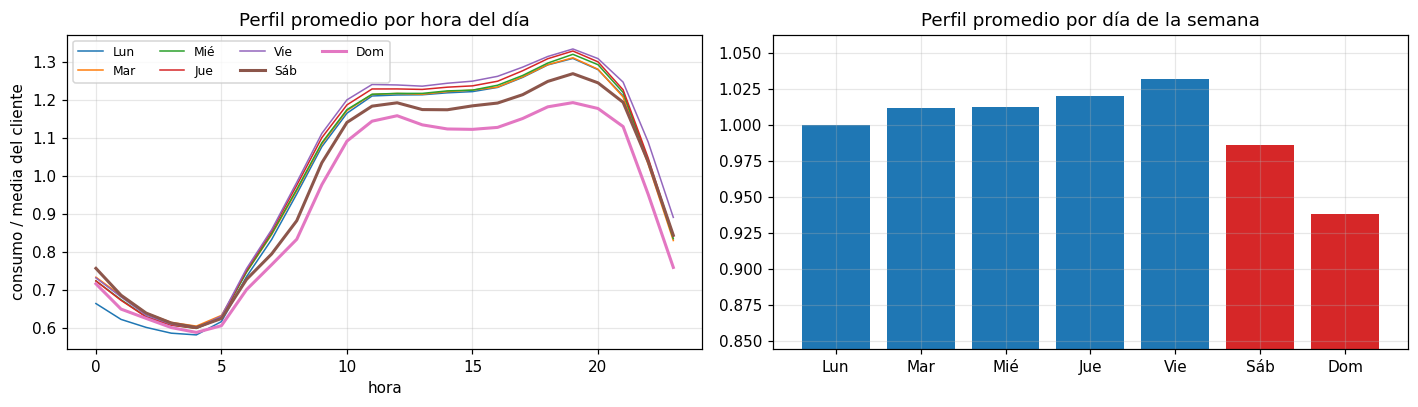

In [50]:
try:
    import holidays
    HOLIDAYS = pd.to_datetime(sorted(holidays.Portugal(years=range(2011, 2016)).keys()))
except ImportError:   # respaldo: feriados nacionales (2013–2015 se suspendieron Corpus Christi, 5-oct, 1-nov y 1-dic)
    HOLIDAYS = pd.to_datetime([
        '2012-01-01','2012-04-06','2012-04-08','2012-04-25','2012-05-01','2012-06-07','2012-06-10','2012-08-15',
        '2012-10-05','2012-11-01','2012-12-01','2012-12-08','2012-12-25',
        '2013-01-01','2013-03-29','2013-03-31','2013-04-25','2013-05-01','2013-06-10','2013-08-15','2013-12-08','2013-12-25',
        '2014-01-01','2014-04-18','2014-04-20','2014-04-25','2014-05-01','2014-06-10','2014-08-15','2014-12-08','2014-12-25'])
HOLIDAYS = HOLIDAYS[(HOLIDAYS >= PERIOD_START) & (HOLIDAYS <= PERIOD_END)]
print(len(HOLIDAYS), 'feriados en el periodo'); print(list(HOLIDAYS.strftime('%Y-%m-%d')))

# consumo relativo: cada cliente dividido por su media de entrenamiento (para que todos pesen igual)
rel  = panel / panel.iloc[:t_val].mean()
prof = rel.mean(1)
DOW  = ['Lun','Mar','Mié','Jue','Vie','Sáb','Dom']

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
hw = prof.iloc[:t_val].groupby([prof.index[:t_val].hour, prof.index[:t_val].dayofweek]).mean().unstack()
for d in range(7):
    ax[0].plot(hw.index, hw[d], label=DOW[d], lw=2 if d >= 5 else 1)
ax[0].set(title='Perfil promedio por hora del día', xlabel='hora', ylabel='consumo / media del cliente'); ax[0].legend(ncol=4, fontsize=8)
dw = prof.iloc[:t_val].groupby(prof.index[:t_val].dayofweek).mean()
ax[1].bar(DOW, dw.values, color=['C0']*5 + ['C3']*2); ax[1].set(title='Perfil promedio por día de la semana', ylim=(dw.min()*0.9, dw.max()*1.03))
savefig('perfil_hora_dia')

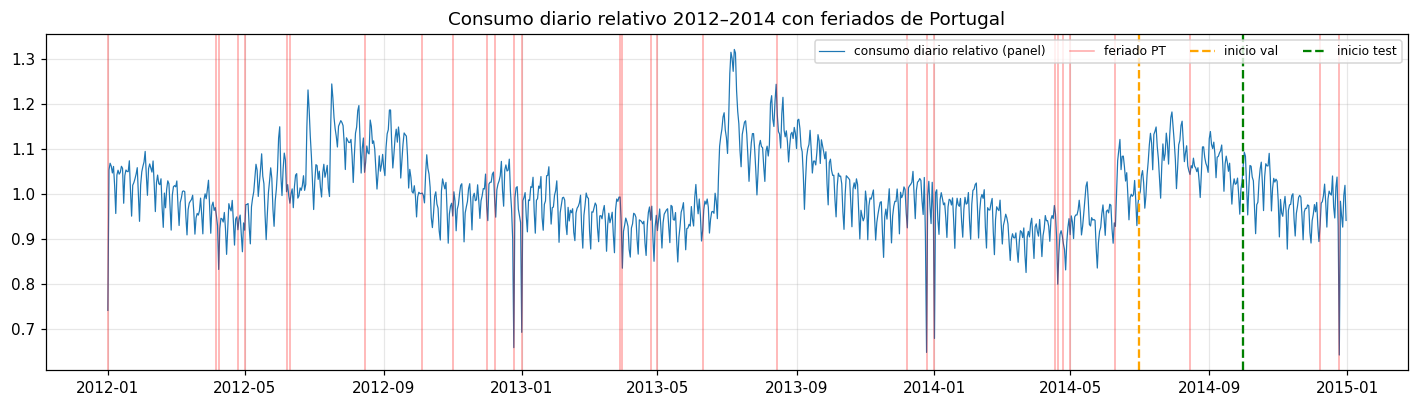

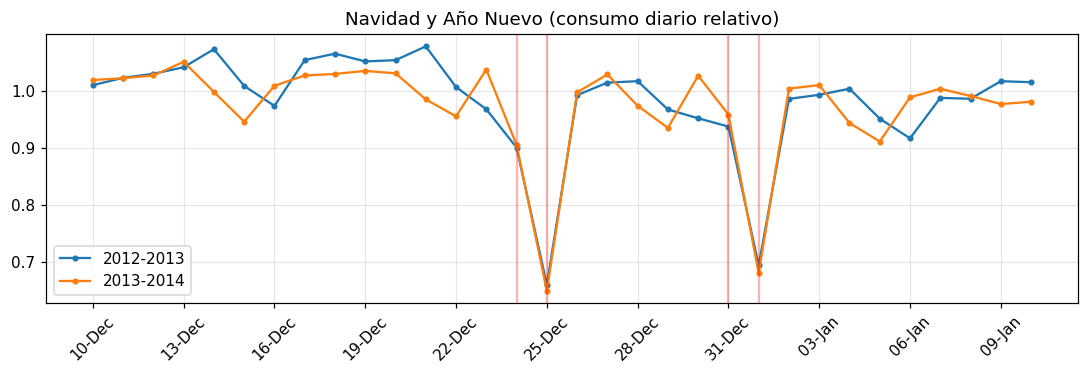

Cambio vs. el mismo día de la semana de las 4 semanas previas:


,2012-13 (%),2013-14 (%)
12-24,-11.600000,-9.700000
12-25,-35.799999,-35.700001
12-26,-3.700000,-1.800000
12-31,-6.000000,-2.800000
01-01,-26.500000,-26.500000


In [51]:
daily_rel = prof.resample('D').mean()
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(daily_rel.index, daily_rel.values, lw=.8, label='consumo diario relativo (panel)')
for i, d in enumerate(HOLIDAYS):
    ax.axvline(d, color='red', alpha=.35, lw=1, label='feriado PT' if i == 0 else None)
for s, c, lab in [(VAL_START, 'orange', 'inicio val'), (TEST_START, 'green', 'inicio test')]:
    ax.axvline(s, color=c, ls='--', label=lab)
ax.set(title='Consumo diario relativo 2012–2014 con feriados de Portugal'); ax.legend(fontsize=8, ncol=4)
savefig('serie_diaria_feriados')

fig, ax = plt.subplots(figsize=(10, 3.5))
for y in (2012, 2013):
    w = daily_rel[f'{y}-12-10':f'{y+1}-01-10']
    ax.plot(np.arange(len(w)), w.values, marker='o', ms=3, label=f'{y}-{y+1}')
    xt = w.index
ax.set_xticks(np.arange(len(xt))[::3]); ax.set_xticklabels(xt.strftime('%d-%b')[::3], rotation=45)
for d in ['12-24', '12-25', '12-31', '01-01']:
    pos = list(xt.strftime('%m-%d')).index(d); ax.axvline(pos, color='red', alpha=.3)
ax.set(title='Navidad y Año Nuevo (consumo diario relativo)'); ax.legend()
savefig('navidad')

def holiday_effect(day):
    day = pd.Timestamp(day); ref = [day - pd.Timedelta(weeks=k) for k in range(1, 5)]
    return 100 * (daily_rel[day] / daily_rel[ref].mean() - 1)
eff = pd.DataFrame({y: {d: holiday_effect(f'{y if d[:2]=="12" else y+1}-{d}') for d in ['12-24','12-25','12-26','12-31','01-01']}
                    for y in (2012, 2013)}).round(1)
eff.columns = ['2012-13 (%)', '2013-14 (%)']
print('Cambio vs. el mismo día de la semana de las 4 semanas previas:'); display(eff)

### 2.5 Escalas entre clientes y normalización

Consumo promedio por cliente en entrenamiento (kWh/h):
min           8.077
mediana     152.623
max        5649.908
dtype: float64
Razón máximo/mínimo: 700x


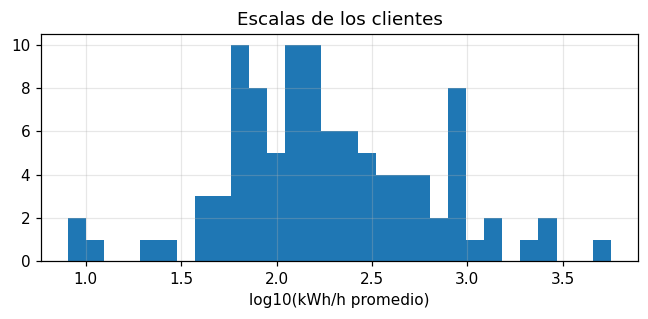

In [52]:
mean_train = Y_raw[:, :t_val].mean(1)
scale_tbl = pd.Series(mean_train).describe(percentiles=[.5])[['min', '50%', 'max']].rename({'50%': 'mediana'})
print('Consumo promedio por cliente en entrenamiento (kWh/h):'); print(scale_tbl.round(3))
print(f'Razón máximo/mínimo: {mean_train.max()/mean_train.min():,.0f}x')
plt.figure(figsize=(6, 3)); plt.hist(np.log10(mean_train), bins=30); plt.xlabel('log10(kWh/h promedio)'); plt.title('Escalas de los clientes')
savefig('escalas')

**Decisión:** z-score **por serie** con media y desviación de **entrenamiento** (`PanelScaler('series')`). Con escalas que difieren varios órdenes de magnitud, una normalización global haría que la pérdida la dominen los clientes grandes; la normalización por ventana (RevIN) se evalúa como iteración en 5.2.

In [53]:
class PanelScaler:
    '''Normalización del panel. Los estadísticos se calculan SOLO con Y[:, :t_end] (entrenamiento).
    mode: 'series' (z-score por cliente) | 'global' (un único mu/sigma)'''
    def __init__(self, mode='series'):
        self.mode = mode
    def fit(self, Y, t_end):
        ref = Y[:, :t_end]
        if self.mode == 'global':
            self.mu = np.full(Y.shape[0], ref.mean(), np.float32); self.sd = np.full(Y.shape[0], ref.std(), np.float32)
        else:
            self.mu = ref.mean(1).astype(np.float32); self.sd = (ref.std(1) + 1e-6).astype(np.float32)
        return self
    def transform(self, Y):
        return ((Y - self.mu[:, None]) / self.sd[:, None]).astype(np.float32)
    def inverse(self, Z, series=None):
        mu, sd = (self.mu, self.sd) if series is None else (self.mu[series], self.sd[series])
        shp = (-1,) + (1,) * (Z.ndim - 1)
        return Z * sd.reshape(shp) + mu.reshape(shp)

In [54]:
def calendar_features(idx):
    h, d, m = idx.hour.values, idx.dayofweek.values, idx.month.values
    hol = np.isin(idx.normalize(), HOLIDAYS)
    return pd.DataFrame({
        'hour_sin': np.sin(2*np.pi*h/24),  'hour_cos': np.cos(2*np.pi*h/24),
        'dow_sin':  np.sin(2*np.pi*d/7),   'dow_cos':  np.cos(2*np.pi*d/7),
        'month_sin': np.sin(2*np.pi*(m-1)/12), 'month_cos': np.cos(2*np.pi*(m-1)/12),
        'weekend': (d >= 5), 'holiday': hol}, index=idx).astype(np.float32)

CAL_DF = calendar_features(DATES); CAL_DF.index.name = 'ds'
CAL    = CAL_DF.values                     # (T, C)
C      = CAL.shape[1]; CAL_COLS = list(CAL_DF.columns)
CAL_INT = np.column_stack([DATES.hour, DATES.dayofweek, DATES.month, CAL_DF['holiday'], CAL_DF['weekend']]).astype(np.float32)
CAL_DF.head(3)

,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,weekend,holiday
ds,,,,,,,,
2012-01-01 00:00:00,0.000000,1.000000,-0.781832,0.62349,0.0,1.0,1.0,1.0
2012-01-01 01:00:00,0.258819,0.965926,-0.781832,0.62349,0.0,1.0,1.0,1.0
2012-01-01 02:00:00,0.500000,0.866025,-0.781832,0.62349,0.0,1.0,1.0,1.0


In [55]:
class WindowDataset(Dataset):
    def __init__(self, Y, cal, L, H, t_start, t_end, stride=1, series=None):
        self.Y, self.cal = torch.as_tensor(Y, dtype=torch.float32), torch.as_tensor(cal, dtype=torch.float32)
        self.L, self.H = L, H
        first = max(t_start, L)
        first = t_start + int(math.ceil((first - t_start) / stride)) * stride      # alineado (stride=24 → 00:00)
        self.origins = torch.arange(first, t_end - H + 1, stride)                   # t = primera hora pronosticada
        self.series  = torch.arange(Y.shape[0]) if series is None else torch.as_tensor(series)
        self.n_o = len(self.origins)
    def __len__(self):
        return len(self.series) * self.n_o
    def _gather(self, idx):                     # versión vectorizada (un batch completo a la vez)
        idx = torch.as_tensor(idx)
        s, t = self.series[idx // self.n_o], self.origins[idx % self.n_o]
        past = t[:, None] + torch.arange(-self.L, 0)
        fut  = t[:, None] + torch.arange(0, self.H)
        x  = torch.cat([self.Y[s[:, None], past].unsqueeze(-1), self.cal[past]], -1)
        return x, self.cal[fut], self.Y[s[:, None], fut], s, t
    def __getitem__(self, i):
        return tuple(v[0] for v in self._gather([i]))
    def __getitems__(self, idxs):               # DataLoader lo usa para pedir el batch completo
        return self._gather(idxs)

def identity_collate(b): return b

ds_tr = WindowDataset(Y_raw, CAL, L, H, 0,      t_val,  stride=1)
ds_va = WindowDataset(Y_raw, CAL, L, H, t_val,  t_test, stride=1)
ds_te = WindowDataset(Y_raw, CAL, L, H, t_test, T,      stride=1)
win = pd.DataFrame({'bloque': ['train', 'val', 'test'],
                    'ventanas por serie': [d.n_o for d in (ds_tr, ds_va, ds_te)],
                    'ventanas panel': [len(d) for d in (ds_tr, ds_va, ds_te)]})
print(f'L={L}, H={H}, stride=1h, {N} clientes'); display(win)
x, xf, y, s, t = next(iter(DataLoader(ds_tr, batch_size=4, shuffle=True, collate_fn=identity_collate)))
print('X', tuple(x.shape), '| XF', tuple(xf.shape), '| y', tuple(y.shape))

L=168, H=24, stride=1h, 100 clientes


,bloque,ventanas por serie,ventanas panel
0,train,21697,2169700
1,val,2185,218500
2,test,2185,218500


X (4, 168, 9) | XF (4, 24, 8) | y (4, 24)


In [56]:
B, Lx, Fx = 4, 168, 1 + C
lstm = nn.LSTM(input_size=Fx, hidden_size=64, num_layers=2, batch_first=True, dropout=0.1)
out, (h_n, c_n) = lstm(torch.randn(B, Lx, Fx))
print('LSTM  output', tuple(out.shape), '(B,L,hidden) | h_n', tuple(h_n.shape), '(layers,B,hidden) | c_n', tuple(c_n.shape))
gru = nn.GRU(Fx, 64, 2, batch_first=True); o, hn = gru(torch.randn(B, Lx, Fx)); print('GRU   output', tuple(o.shape), '| h_n', tuple(hn.shape), '(sin c_n)')

def tcn_receptive_field(kernel, dilations, convs_per_block=2):
    return 1 + convs_per_block * (kernel - 1) * sum(dilations)
k, dil = 3, [1, 2, 4, 8, 16, 32]
conv = nn.Conv1d(8, 8, kernel_size=k, dilation=4, padding=(k - 1) * 4)    # padding causal = (k-1)·d, luego recortar a la derecha
z = conv(torch.randn(1, 8, 100))[..., :100]
print('Conv1d causal', tuple(z.shape), '| campo receptivo TCN k=3, d=1..32, 2 conv/bloque:', tcn_receptive_field(k, dil), 'h')

enc = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=128, batch_first=True)
print('TransformerEncoderLayer', tuple(enc(torch.randn(B, 21, 64)).shape), '(B, n_patches, d_model)')

LSTM  output (4, 168, 64) (B,L,hidden) | h_n (2, 4, 64) (layers,B,hidden) | c_n (2, 4, 64)
GRU   output (4, 168, 64) | h_n (2, 4, 64) (sin c_n)
Conv1d causal (1, 8, 100) | campo receptivo TCN k=3, d=1..32, 2 conv/bloque: 253 h
TransformerEncoderLayer (4, 21, 64) (B, n_patches, d_model)


In [57]:
QLEVELS = np.array([0.1, 0.5, 0.9])
SCALE24 = np.mean(np.abs(Y_raw[:, 24:t_val] - Y_raw[:, :t_val - 24]), axis=1)   # denominador MASE (solo train)

class Forecaster:
    name, family, strategy, covariates = 'base', '', 'multi-salida', False
    L = None; H = H; train_time = 0.0; n_params = (0, 0); peak_mem = 0.0
    def fit(self, Y, t_train_end, t_val_end): return self
    def predict(self, hist, t): raise NotImplementedError

def backtest(model, origins=TEST_ORIGINS, Y=Y_raw, h=None):
    h = h or model.H
    preds, qs = [], []
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    t0 = time.perf_counter()
    if hasattr(model, 'predict_many'):                    # estadísticos: mismo protocolo vía cross_validation (más rápido)
        P = model.predict_many(Y, origins, h)
    else:
        for t in origins:
            hist = Y[:, :t]                               # solo datos hasta las 23:00 del día anterior
            out = model.predict(hist, int(t))
            if isinstance(out, dict): preds.append(out['mean'][:, :h]); qs.append(out['q'][:, :h])
            else: preds.append(out[:, :h])
        bad = [p.shape for p in preds if p.shape != (Y.shape[0], h)]
        if bad: raise ValueError(f'predicción con forma {bad[0]}; se esperaba {(Y.shape[0], h)}')
        P = np.stack(preds, 1)
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    idx = origins[:, None] + np.arange(h)                 # (O, h)
    return dict(yhat=P.astype(np.float64), y=Y[:, idx].astype(np.float64), origins=origins, h=h,
                q=np.stack(qs, 1) if qs else None, inf_time=time.perf_counter() - t0)

def evaluate(res, mask=None):
    y, p = res['y'], res['yhat']; e = p - y; ae = np.abs(e)
    m = np.ones_like(y, bool) if mask is None else np.broadcast_to(mask, y.shape)
    nz = m & (y > 0)
    mae_s = np.nanmean(np.where(m, ae, np.nan), axis=(1, 2))
    mape_s = np.nanmean(np.where(nz, ae / np.where(y > 0, y, 1), np.nan), axis=(1, 2)) * 100
    out = dict(MAE=ae[m].mean(), RMSE=np.sqrt((e[m]**2).mean()), WAPE=ae[m].sum() / np.abs(y[m]).sum(),
               MAPE=np.nanmean(np.where(nz, ae / np.where(y > 0, y, 1), np.nan)) * 100,
               MAPE_peor_cliente=np.nanmax(mape_s), MASE=np.nanmean(mae_s / SCALE24))
    if res.get('q') is not None:
        q = res['q']; yq = y[..., None]
        pin = np.maximum(QLEVELS * (yq - q), (QLEVELS - 1) * (yq - q))
        out['Pinball'] = pin[m].mean()
        out['Cobertura_P10_P90'] = ((y >= q[..., 0]) & (y <= q[..., 2]))[m].mean()
    return out

def per_client(res):
    e = res['yhat'] - res['y']
    return pd.DataFrame({'cliente': CLIENTS, 'MAE': np.abs(e).mean((1, 2)), 'RMSE': np.sqrt((e**2).mean((1, 2))),
                         'MASE': np.abs(e).mean((1, 2)) / SCALE24})

def ds_grid(res):    return DATES.values[res['origins'][:, None] + np.arange(res['h'])]   # (O, h) datetime64
def per_step(res):   return np.abs(res['yhat'] - res['y']).mean((0, 1))           # MAE por h = 1..H
def per_hour(res):
    hours = pd.DatetimeIndex(ds_grid(res).ravel()).hour.values.reshape(len(res['origins']), res['h'])
    ae = np.abs(res['yhat'] - res['y'])
    return pd.Series([ae[:, hours == hh].mean() for hh in range(24)], index=range(24))
def dec_mask(res):
    ds = ds_grid(res)
    return (ds >= np.datetime64('2014-12-22')) & (ds < np.datetime64('2014-12-29'))

RESULTS = {}
def register(model, res, **info):
    met = evaluate(res); met['MASE_dic22_28'] = evaluate(res, dec_mask(res))['MASE']
    RESULTS[model.name] = dict(model=model, res=res, metrics=met, family=model.family, L=model.L,
                               strategy=model.strategy, covariates=model.covariates, train_time=model.train_time,
                               n_params=model.n_params, peak_mem=model.peak_mem, inf_time=res['inf_time'], **info)
    print(f"{model.name:<22} MAE={met['MAE']:.3f}  RMSE={met['RMSE']:.3f}  WAPE={met['WAPE']:.3%}  MASE={met['MASE']:.3f}"
          f"  | train {model.train_time:.1f}s  inf {res['inf_time']:.1f}s")
    return met

def to_long(Yblock, t0, ids=None):
    ids = CLIENTS if ids is None else ids; n = Yblock.shape[1]
    return pd.DataFrame({'unique_id': np.repeat(ids, n), 'ds': np.tile(DATES[t0:t0 + n].values, len(ids)),
                         'y': Yblock.ravel().astype(np.float32)})
def with_calendar(df): return df.join(CAL_DF, on='ds')
def future_frame(t, h=H):
    return pd.DataFrame({'unique_id': np.repeat(CLIENTS, h), 'ds': np.tile(DATES[t:t + h].values, N)})

def history_start(t_end, months):
    if months is None: return 0
    return int(max(0, DATES.searchsorted(DATES[t_end] - pd.DateOffset(months=months))))

def count_params(net):
    return (sum(p.numel() for p in net.parameters()), sum(p.numel() for p in net.parameters() if p.requires_grad))

**Reentrenamiento mensual (ventana expandible).** Para el origen de cada mes (oct, nov, dic) se reentrena con todo lo anterior: train hasta 3 meses antes del inicio del mes y los últimos 3 meses como validación (early stopping). Para octubre coincide con el modelo original.

In [58]:
MONTH_STARTS = [DATES.get_loc(pd.Timestamp(d)) for d in ('2014-10-01', '2014-11-01', '2014-12-01')] + [T]

def backtest_monthly_refit(factory):
    parts, tt = [], 0.0
    for a, b in zip(MONTH_STARTS[:-1], MONTH_STARTS[1:]):
        m = factory(); t0 = time.perf_counter()
        m.fit(Y_raw, a - 92 * 24, a); tt += time.perf_counter() - t0
        parts.append(backtest(m, origins=np.arange(a, b - H + 1, 24)))
    res = dict(yhat=np.concatenate([p['yhat'] for p in parts], 1), y=np.concatenate([p['y'] for p in parts], 1),
               origins=np.concatenate([p['origins'] for p in parts]), h=H, q=None,
               inf_time=sum(p['inf_time'] for p in parts))
    res['train_time'] = tt
    return res

In [59]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, MSTL, AutoETS

class SFForecaster(Forecaster):
    family = 'Baseline'
    def __init__(self, model, name, ctx, h=H):
        self.model, self.name, self.ctx, self.H, self.L = model, name, ctx, h, ctx
    def predict(self, hist, t):                       # un origen (usado en la verificación)
        t0 = t - self.ctx
        fc = StatsForecast(models=[self.model], freq='h', n_jobs=1).forecast(df=to_long(hist[:, t0:], t0), h=self.H)
        if 'unique_id' not in fc.columns: fc = fc.reset_index()
        return fc.pivot(index='unique_id', columns='ds', values=self.name).loc[CLIENTS].values
    def predict_many(self, Y, origins, h):
        '''Todos los orígenes en una llamada: cross_validation re-estima el modelo en cada corte usando solo
        las últimas `ctx` horas anteriores al corte (input_size), igual que predict() origen por origen.'''
        step = int(origins[1] - origins[0]) if len(origins) > 1 else h
        a, b = int(origins[0]) - self.ctx, int(origins[-1]) + h
        cv = StatsForecast(models=[self.model], freq='h', n_jobs=-1).cross_validation(
            df=to_long(Y[:, a:b], a), h=h, n_windows=len(origins), step_size=step, input_size=self.ctx, refit=True)
        if 'unique_id' not in cv.columns: cv = cv.reset_index()
        cv = cv.sort_values(['unique_id', 'cutoff', 'ds'])
        cv['unique_id'] = pd.Categorical(cv['unique_id'], categories=CLIENTS, ordered=True)
        return cv.sort_values(['unique_id', 'cutoff', 'ds'])[self.name].values.reshape(len(CLIENTS), len(origins), h)

baselines = [SFForecaster(Naive(alias='Naive'), 'Naive', 48),
             SFForecaster(SeasonalNaive(24, alias='SNaive24'), 'SNaive24', 24 * 7),
             SFForecaster(SeasonalNaive(168, alias='SNaive168'), 'SNaive168', 24 * 14),
             SFForecaster(MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model='ZZN'), alias='MSTL'), 'MSTL', 24 * 7 * (2 if LITE else 4))]
if FAST: baselines = baselines[:3]      # MSTL tarda (~0.3 s por serie y origen); se omite solo en modo de prueba
VAL_SCORES = {}
for m in baselines:
    VAL_SCORES[m.name] = evaluate(backtest(m, VAL_ORIGINS))['MASE']
    register(m, backtest(m))

Naive                  MAE=117.142  RMSE=260.131  WAPE=31.030%  MASE=4.093  | train 0.0s  inf 0.6s
SNaive24               MAE=30.891  RMSE=90.640  WAPE=8.183%  MASE=1.011  | train 0.0s  inf 0.6s
SNaive168              MAE=33.265  RMSE=99.772  WAPE=8.812%  MASE=1.072  | train 0.0s  inf 0.6s
MSTL                   MAE=29.951  RMSE=84.247  WAPE=7.934%  MASE=0.962  | train 0.0s  inf 1100.4s


In [60]:
# Verificación: predict() origen por origen (forecast) == backtest vía cross_validation
chk = RESULTS['SNaive24']['res']; o5 = TEST_ORIGINS[:5]
loop = np.stack([baselines[1].predict(Y_raw[:, :t], int(t)) for t in o5], 1)
print('máx |diferencia| en 5 orígenes:', np.abs(loop - chk['yhat'][:, :5]).max())

máx |diferencia| en 5 orígenes: 0.0


In [61]:
import lightgbm as lgb

class LGBMForecaster(Forecaster):
    family, strategy, covariates = 'Árboles', 'directa (h como feature)', True
    def __init__(self, name='LightGBM', months=None, origin_stride=72 if LITE else 24, n_estimators=None, seed=SEED):
        self.name, self.months, self.stride, self.n_est, self.seed, self.L = name, months, origin_stride, n_estimators, seed, 168
    @staticmethod
    def feats(Yn, origins, series):
        S, O = np.repeat(series, len(origins)), np.tile(origins, len(series))
        lag = Yn[S[:, None], O[:, None] - np.arange(1, 25)]
        cs = np.concatenate([np.zeros((Yn.shape[0], 1), np.float64), np.cumsum(Yn, 1, dtype=np.float64)], 1)
        r24, r168 = (cs[S, O] - cs[S, O - 24]) / 24, (cs[S, O] - cs[S, O - 168]) / 168
        hh = np.tile(np.arange(1, H + 1), len(S)); Sr = np.repeat(S, H); tt = np.repeat(O, H) + hh - 1
        X = np.column_stack([np.repeat(lag, H, 0), np.repeat(r24, H), np.repeat(r168, H),
                             Yn[Sr, tt - 24], Yn[Sr, tt - 168], hh, CAL_INT[tt], Sr]).astype(np.float32)
        return X, Sr, tt
    COLS = [f'lag{i}' for i in range(1, 25)] + ['mean24', 'mean168', 'lag24_obj', 'lag168_obj', 'h',
            'hour', 'dow', 'month', 'holiday', 'weekend', 'sid']
    def fit(self, Y, t_train_end, t_val_end):
        Y = Y[:, :t_val_end]
        self.scaler = PanelScaler('series').fit(Y, t_train_end); Yn = self.scaler.transform(Y)
        s0 = history_start(t_train_end, self.months) + 168
        o_tr = np.arange(int(math.ceil(s0 / 24)) * 24, t_train_end - H + 1, self.stride)
        Xtr, S, tt = self.feats(Yn, o_tr, np.arange(N)); ytr = Yn[S, tt]
        params = dict(objective='l2', learning_rate=0.05, num_leaves=127, min_child_samples=100, subsample=0.8,
                      subsample_freq=1, colsample_bytree=0.8, n_estimators=self.n_est or (100 if FAST else (600 if LITE else 2000)),
                      random_state=self.seed, verbose=-1)
        self.model = lgb.LGBMRegressor(**params); t0 = time.perf_counter()
        if t_val_end > t_train_end:
            Xva, Sv, tv = self.feats(Yn, np.arange(t_train_end, t_val_end - H + 1, 24), np.arange(N))
            self.model.fit(pd.DataFrame(Xtr, columns=self.COLS), ytr, eval_set=[(pd.DataFrame(Xva, columns=self.COLS), Yn[Sv, tv])],
                           categorical_feature=['sid'], callbacks=[lgb.early_stopping(50, verbose=False)])
        else:
            self.model.fit(pd.DataFrame(Xtr, columns=self.COLS), ytr, categorical_feature=['sid'])
        self.train_time = time.perf_counter() - t0
        nodes = sum(t['num_leaves'] * 2 - 1 for t in self.model.booster_.dump_model()['tree_info'])
        self.n_params = (nodes, nodes)        # "parámetros" ≈ nodos de los árboles
        return self
    def predict(self, hist, t):
        Yn = self.scaler.transform(hist)
        X, S, tt = self.feats(Yn, np.array([t]), np.arange(N))
        z = self.model.predict(pd.DataFrame(X, columns=self.COLS)).reshape(N, H)
        return self.scaler.inverse(z)

lgbm = LGBMForecaster().fit(Y_raw, t_val, t_test)
VAL_SCORES['LightGBM'] = evaluate(backtest(lgbm, VAL_ORIGINS))['MASE']
register(lgbm, backtest(lgbm))

LightGBM               MAE=23.467  RMSE=66.129  WAPE=6.216%  MASE=0.780  | train 75.8s  inf 24.8s


{'MAE': np.float64(23.46714099116343),
 'RMSE': np.float64(66.12881394897495),
 'WAPE': np.float64(0.06216321883254156),
 'MAPE': np.float64(8.489738448263434),
 'MAPE_peor_cliente': np.float64(54.68858901193675),
 'MASE': np.float64(0.7795061482602234),
 'MASE_dic22_28': np.float64(1.3114845217083582)}

In [62]:
class RevIN(nn.Module):
    '''Reversible Instance Normalization sobre el canal y: normaliza cada ventana con su media/desv. y revierte la salida.'''
    def __init__(self):
        super().__init__(); self.g = nn.Parameter(torch.ones(1)); self.b = nn.Parameter(torch.zeros(1))
    def forward(self, x, y=None):
        v = x[..., 0]; mu = v.mean(1, keepdim=True).detach(); sd = (v.std(1, keepdim=True) + 1e-5).detach()
        x = torch.cat([((v - mu) / sd * self.g + self.b).unsqueeze(-1), x[..., 1:]], -1)
        y = None if y is None else (y - mu) / sd * self.g + self.b
        return x, y, (mu, sd)
    def inverse(self, out, st):
        mu, sd = st; return (out - self.b) / (self.g + 1e-6) * sd + mu

class ForecastNet(nn.Module):
    def __init__(self, revin=False):
        super().__init__(); self.revin = RevIN() if revin else None
    def forward(self, x, xf, y=None):
        if self.revin is None: return self.core(x, xf, y)
        x, y, st = self.revin(x, y); return self.revin.inverse(self.core(x, xf, y), st)

class MLP(ForecastNet):                       # multi-salida, usa historia + calendario pasado y futuro
    def __init__(self, L, H, F, C, hidden=512, layers=2, dropout=0.1, revin=False, **kw):
        super().__init__(revin); dims, blocks = [L * F + H * C] + [hidden] * layers, []
        for a, b in zip(dims[:-1], dims[1:]): blocks += [nn.Linear(a, b), nn.ReLU(), nn.Dropout(dropout)]
        self.net = nn.Sequential(*blocks, nn.Linear(dims[-1], H))
    def core(self, x, xf, y=None): return self.net(torch.cat([x.flatten(1), xf.flatten(1)], 1))

class MovingAvg(nn.Module):
    def __init__(self, k): super().__init__(); self.k = k; self.pool = nn.AvgPool1d(k, stride=1)
    def forward(self, v):
        p = (self.k - 1) // 2
        v = torch.cat([v[:, :1].repeat(1, p), v, v[:, -1:].repeat(1, self.k - 1 - p)], 1)
        return self.pool(v.unsqueeze(1)).squeeze(1)

class DLinear(ForecastNet):                   # tendencia (media móvil) + estacional, una capa lineal L→H cada una
    def __init__(self, L, H, kernel=25, revin=False, **kw):
        super().__init__(revin); self.ma = MovingAvg(kernel); self.ls = nn.Linear(L, H); self.lt = nn.Linear(L, H)
    def core(self, x, xf, y=None):
        v = x[..., 0]; tr = self.ma(v); return self.ls(v - tr) + self.lt(tr)

class NLinear(ForecastNet):                   # resta el último valor, lineal L→H, lo suma de vuelta
    def __init__(self, L, H, revin=False, **kw):
        super().__init__(revin); self.lin = nn.Linear(L, H)
    def core(self, x, xf, y=None):
        v = x[..., 0]; last = v[:, -1:]; return self.lin(v - last) + last

def _lstm(F, hidden, layers, dropout):
    return nn.LSTM(F, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0.0)

class LSTMMultiOutput(ForecastNet):           # encoder LSTM → h_n[-1] + calendario futuro → densa con H salidas
    def __init__(self, L, H, F, C, hidden=128, layers=2, dropout=0.1, revin=False, **kw):
        super().__init__(revin); self.lstm = _lstm(F, hidden, layers, dropout)
        self.head = nn.Sequential(nn.Linear(hidden + H * C, hidden), nn.ReLU(), nn.Linear(hidden, H))
    def core(self, x, xf, y=None):
        _, (h_n, _) = self.lstm(x); return self.head(torch.cat([h_n[-1], xf.flatten(1)], 1))

class LSTMAutoregressive(ForecastNet):        # un paso: [y_i, cal_{i+1}] → y_{i+1}; train con teacher forcing, inferencia recursiva
    def __init__(self, L, H, F, C, hidden=128, layers=2, dropout=0.1, revin=False, **kw):
        super().__init__(revin); self.H = H; self.lstm = _lstm(1 + C, hidden, layers, dropout); self.head = nn.Linear(hidden, 1)
    def core(self, x, xf, y=None):
        cal_next = torch.cat([x[:, 1:, 1:], xf[:, :1]], 1)
        enc_in = torch.cat([x[..., :1], cal_next], -1)
        if self.training and y is not None:
            dec_in = torch.cat([y[:, :-1, None], xf[:, 1:]], -1)
            out, _ = self.lstm(torch.cat([enc_in, dec_in], 1))
            return self.head(out[:, -self.H:]).squeeze(-1)
        out, st = self.lstm(enc_in); p = self.head(out[:, -1:]); preds = [p]
        for k in range(1, self.H):
            out, st = self.lstm(torch.cat([p, xf[:, k:k + 1]], -1), st); p = self.head(out); preds.append(p)
        return torch.cat(preds, 1).squeeze(-1)

class Seq2Seq(ForecastNet):                   # encoder LSTM → decoder LSTM con [y_{k-1}, calendario_k]
    def __init__(self, L, H, F, C, hidden=128, layers=2, dropout=0.1, revin=False, tf_ratio=0.5, **kw):
        super().__init__(revin); self.H, self.tf = H, tf_ratio
        self.enc = _lstm(F, hidden, layers, dropout); self.dec = _lstm(1 + C, hidden, layers, dropout); self.head = nn.Linear(hidden, 1)
    def core(self, x, xf, y=None):
        _, st = self.enc(x); prev = x[:, -1:, :1]; outs = []
        tf = self.training and y is not None
        for k in range(self.H):
            o, st = self.dec(torch.cat([prev, xf[:, k:k + 1]], -1), st); p = self.head(o); outs.append(p)
            prev = y[:, k:k + 1, None] if (tf and random.random() < self.tf) else p   # teacher forcing estocástico
        return torch.cat(outs, 1).squeeze(-1)

NETS = {'MLP': MLP, 'DLinear': DLinear, 'NLinear': NLinear, 'LSTM-MO': LSTMMultiOutput,
        'LSTM-AR': LSTMAutoregressive, 'Seq2Seq': Seq2Seq}
NET_INFO = {'MLP': ('MLP/lineal', 'multi-salida', True), 'DLinear': ('MLP/lineal', 'multi-salida', False),
            'NLinear': ('MLP/lineal', 'multi-salida', False), 'LSTM-MO': ('Recurrente', 'multi-salida', True),
            'LSTM-AR': ('Recurrente', 'autorregresiva', True), 'Seq2Seq': ('Encoder-decoder', 'seq2seq', True)}

In [63]:
BASE_CFG = dict(L=168, H=24, norm='series', hidden=128, layers=2, dropout=0.1, lr=1e-3, wd=1e-4, batch=256,
                epochs=40, steps=300, patience=6, months=None, seed=SEED, series=None, net_kw={})
if FAST: BASE_CFG.update(epochs=2, steps=15, patience=1)
if LITE: BASE_CFG.update(epochs=15, steps=150, patience=3)

@torch.no_grad()
def predict_windows(net, ds, bs=2048):
    net.eval(); P, Yt = [], []
    for i in range(0, len(ds), bs):
        x, xf, y, s, t = ds._gather(torch.arange(i, min(i + bs, len(ds))))
        P.append(net(x.to(DEVICE), xf.to(DEVICE)).cpu()); Yt.append(y)
    return torch.cat(P).numpy(), torch.cat(Yt).numpy()

def train_net(net, Yn, cfg, scaler, t_start, t_train_end, t_val_end):
    g = torch.Generator().manual_seed(cfg['seed'])
    tr = WindowDataset(Yn, CAL, cfg['L'], cfg['H'], t_start + cfg['L'], t_train_end, 1, cfg['series'])
    dl = DataLoader(tr, batch_size=cfg['batch'], collate_fn=identity_collate,
                    sampler=RandomSampler(tr, replacement=True, num_samples=cfg['steps'] * cfg['batch'], generator=g))
    va = WindowDataset(Yn, CAL, cfg['L'], cfg['H'], t_train_end, t_val_end, 24, cfg['series']) if t_val_end > t_train_end else None
    opt, lossf = torch.optim.AdamW(net.parameters(), lr=cfg['lr'], weight_decay=cfg['wd']), nn.L1Loss()
    hist, best, best_state, best_ep, bad = [], np.inf, None, cfg['epochs'], 0
    if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats()
    for ep in range(1, cfg['epochs'] + 1):
        t0 = time.perf_counter(); net.train(); tl = 0.0
        for x, xf, y, s, t in dl:
            x, xf, y = x.to(DEVICE), xf.to(DEVICE), y.to(DEVICE)
            loss = lossf(net(x, xf, y), y)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); tl += loss.item()
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        rec = dict(epoch=ep, train_loss=tl / len(dl), epoch_time=time.perf_counter() - t0)
        if va is not None:
            P, Yt = predict_windows(net, va)
            rec['val_loss'] = np.abs(P - Yt).mean()
            ser = va.series.repeat_interleave(va.n_o).numpy()
            ae = np.abs(scaler.inverse(P, ser) - scaler.inverse(Yt, ser)).reshape(len(va.series), va.n_o, -1)
            rec['val_MAE'] = ae.mean(); rec['val_MASE'] = (ae.mean((1, 2)) / SCALE24[va.series.numpy()]).mean()
            if rec['val_loss'] < best - 1e-5:
                best, best_ep, bad, best_state = rec['val_loss'], ep, 0, copy.deepcopy(net.state_dict())
            else:
                bad += 1
        hist.append(rec)
        if va is not None and bad >= cfg['patience']: break
    if best_state is not None: net.load_state_dict(best_state)
    peak = torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == 'cuda' else 0.0
    return pd.DataFrame(hist), best_ep, peak

class TorchForecaster(Forecaster):
    def __init__(self, arch, name=None, **cfg):
        self.arch, self.cfg = arch, {**BASE_CFG, **cfg}
        self.name = name or arch; self.L, self.H = self.cfg['L'], self.cfg['H']
        self.family, self.strategy, self.covariates = NET_INFO[arch]
    def fit(self, Y, t_train_end, t_val_end):
        c = self.cfg; set_seed(c['seed'])
        Y = Y[:, :t_val_end]                                # nada posterior a validación entra al ajuste
        self.scaler = PanelScaler('series' if c['norm'] == 'series' else 'global').fit(Y, t_train_end)
        Yn = self.scaler.transform(Y)
        self.net = NETS[self.arch](L=c['L'], H=c['H'], F=1 + C, C=C, hidden=c['hidden'], layers=c['layers'],
                                   dropout=c['dropout'], revin=(c['norm'] == 'window'), **c['net_kw']).to(DEVICE)
        t0 = time.perf_counter()
        self.history, self.best_epoch, self.peak_mem = train_net(self.net, Yn, c, self.scaler,
                                                                 history_start(t_train_end, c['months']), t_train_end, t_val_end)
        self.train_time = time.perf_counter() - t0; self.n_params = count_params(self.net)
        return self
    @torch.no_grad()
    def predict(self, hist, t):
        Lc = self.cfg['L']; z = self.scaler.transform(hist[:, t - Lc:t]); n = z.shape[0]
        x  = np.concatenate([z[..., None], np.broadcast_to(CAL[t - Lc:t], (n, Lc, C))], -1)
        xf = np.broadcast_to(CAL[t:t + self.H], (n, self.H, C))
        self.net.eval()
        out = self.net(torch.tensor(x, device=DEVICE), torch.tensor(np.ascontiguousarray(xf), device=DEVICE)).cpu().numpy()
        return self.scaler.inverse(out)

def val_mase(model): return evaluate(backtest(model, VAL_ORIGINS))['MASE']

In [64]:
# Fuga 1 — split aleatorio de ventanas: el split es temporal por bloque del OBJETIVO
assert int(ds_tr.origins.max()) + H - 1 < int(ds_va.origins.min()), 'train invade val'
assert int(ds_va.origins.max()) + H - 1 < int(ds_te.origins.min()), 'val invade test'
print('1) último objetivo train:', DATES[int(ds_tr.origins.max()) + H - 1], '< primer objetivo val:', DATES[int(ds_va.origins.min())])

# Fuga 2 — escalar con toda la serie: estadísticos solo con entrenamiento; alterar el futuro no los cambia
sc = PanelScaler('series').fit(Y_raw, t_val)
Y_mod = Y_raw.copy(); Y_mod[:, t_val:] *= 1000
assert np.allclose(PanelScaler('series').fit(Y_mod, t_val).mu, sc.mu)
print('2) mu/sigma idénticos aunque se multiplique val+test por 1000')

# Fuga 3 — early stopping con la prueba: se entrena un modelo con TODO el bloque de prueba en NaN.
#          Si el early stopping o el escalado tocaran test, la pérdida sería NaN.
Y_nan = Y_raw.copy(); Y_nan[:, t_test:] = np.nan
probe = TorchForecaster('NLinear', name='probe', epochs=1, steps=5).fit(Y_nan, t_val, t_test)
assert np.isfinite(probe.history[['train_loss', 'val_loss']].values).all()
print('3) entrenamiento + early stopping finitos con test = NaN →', probe.history[['train_loss', 'val_loss']].round(4).values.tolist())

# Fuga 4 — covariables mal alineadas: la entrada termina a las 23:00 y el calendario futuro empieza a las 00:00 del día pronosticado
x, xf, y, s, t = ds_te._gather([0]); t = int(t[0]); s = int(s[0])
assert DATES[t - 1].hour == 23 and DATES[t].hour == 0
assert np.allclose(x[0, :, 0].numpy(), Y_raw[s, t - L:t]) and np.allclose(xf[0].numpy(), CAL[t:t + H])
assert np.allclose(x[0, :, 1:].numpy(), CAL[t - L:t])
Xl, S_, tt = LGBMForecaster.feats(Y_raw, np.array([t]), np.array([s]))
assert (tt - 24 < t).all() and (tt - 168 < t).all()       # rezagos de LightGBM siempre en el pasado
print('4) entrada', DATES[t - L], '→', DATES[t - 1], '| calendario futuro', DATES[t], '→', DATES[t + H - 1])

# Guardia del backtest: un modelo que intenta leer la hora del origen falla
class Spy(Forecaster):
    def predict(self, hist, t): return hist[:, t:t + H]          # intenta leer el día pronosticado
try:
    backtest(Spy(), TEST_ORIGINS[:1]); print('FUGA!')
except ValueError as e:
    print('backtest: el modelo solo recibe Y[:, :t]; leer el futuro devuelve vacío →', e)

1) último objetivo train: 2014-06-30 23:00:00 < primer objetivo val: 2014-07-01 00:00:00
2) mu/sigma idénticos aunque se multiplique val+test por 1000
3) entrenamiento + early stopping finitos con test = NaN → [[0.9435, 0.7853999733924866]]
4) entrada 2014-09-24 00:00:00 → 2014-09-30 23:00:00 | calendario futuro 2014-10-01 00:00:00 → 2014-10-01 23:00:00
backtest: el modelo solo recibe Y[:, :t]; leer el futuro devuelve vacío → predicción con forma (100, 0); se esperaba (100, 24)


LSTM-AR                MAE=31.676  RMSE=86.786  WAPE=8.391%  MASE=1.028  | train 118.4s  inf 1.8s
LSTM-MO                MAE=30.342  RMSE=77.563  WAPE=8.037%  MASE=1.004  | train 94.0s  inf 0.5s
Seq2Seq                MAE=31.218  RMSE=79.951  WAPE=8.270%  MASE=1.035  | train 222.1s  inf 1.8s


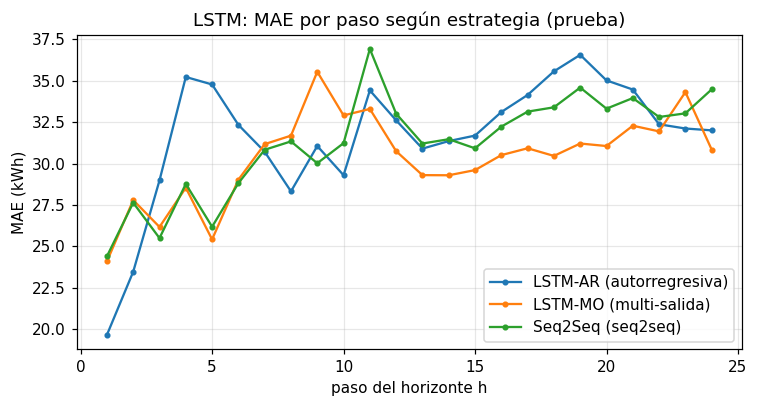

MASE validación: {'LSTM-AR': np.float64(1.1155), 'LSTM-MO': np.float64(1.0753), 'Seq2Seq': np.float64(1.1123)}


In [65]:
strategies = {}
for arch, nm in [('LSTM-AR', 'LSTM-AR'), ('LSTM-MO', 'LSTM-MO'), ('Seq2Seq', 'Seq2Seq')]:
    m = TorchForecaster(arch, name=nm).fit(Y_raw, t_val, t_test)
    VAL_SCORES[nm] = val_mase(m); strategies[nm] = m
    register(m, backtest(m))

plt.figure(figsize=(7, 3.8))
for nm in strategies:
    plt.plot(range(1, H + 1), per_step(RESULTS[nm]['res']), marker='o', ms=3, label=f"{nm} ({RESULTS[nm]['strategy']})")
plt.xlabel('paso del horizonte h'); plt.ylabel('MAE (kWh)'); plt.title('LSTM: MAE por paso según estrategia (prueba)'); plt.legend()
savefig('estrategias_multipaso')
print('MASE validación:', {k: round(VAL_SCORES[k], 4) for k in strategies})

### Resto de modelos propios (configuración base)

In [66]:
own = {}
for arch in ['MLP', 'DLinear', 'NLinear']:
    m = TorchForecaster(arch, hidden=512 if arch == 'MLP' else 128).fit(Y_raw, t_val, t_test)
    VAL_SCORES[arch] = val_mase(m); own[arch] = m
    register(m, backtest(m))

MLP                    MAE=29.199  RMSE=75.174  WAPE=7.735%  MASE=0.964  | train 6.1s  inf 0.1s
DLinear                MAE=27.238  RMSE=77.067  WAPE=7.215%  MASE=0.872  | train 10.1s  inf 0.1s
NLinear                MAE=27.319  RMSE=77.029  WAPE=7.237%  MASE=0.875  | train 9.9s  inf 0.1s


In [67]:
ITER_ARCH = min(strategies, key=lambda k: VAL_SCORES[k])
print('Arquitectura para iteraciones:', ITER_ARCH)
ITERS = [dict(),                         # 1 base
         dict(L=48), dict(L=336),        # 2-3 ventana
         dict(months=3), dict(months=12),# 4-5 historia (30 meses = base)
         dict(norm='global'), dict(norm='window'),   # 6-7 normalización
         dict(hidden=64, layers=1), dict(hidden=256, dropout=0.3),   # 8-9 capacidad
         dict(lr=3e-3, batch=512)]       # 10 optimización
if LITE: ITERS = ITERS[:7]
if FAST: ITERS = [dict(), dict(L=48), dict(months=3)]

iter_models, iter_rows = {}, []
for i, over in enumerate(ITERS, 1):
    m = strategies[ITER_ARCH] if not over else TorchForecaster(ITER_ARCH, name=f'{ITER_ARCH}-it{i}', **over).fit(Y_raw, t_val, t_test)
    r = backtest(m, VAL_ORIGINS); e = evaluate(r); iter_models[i] = m
    c = m.cfg
    iter_rows.append(dict(it=i, cambio=str(over) if over else 'base', L=c['L'], H=c['H'], meses=c['months'] or 30, norm=c['norm'],
                          hidden=c['hidden'], capas=c['layers'], dropout=c['dropout'], lr=c['lr'], batch=c['batch'],
                          epochs=len(m.history), mejor_ep=m.best_epoch, params_tot=m.n_params[0], params_entr=m.n_params[1],
                          t_epoch_s=m.history.epoch_time.mean(), t_total_s=m.train_time, t_inf_92_s=r['inf_time'],
                          gpu_MB=m.peak_mem, train_loss=m.history.train_loss.iloc[m.best_epoch - 1] if m.best_epoch <= len(m.history) else np.nan,
                          val_MAE=e['MAE'], val_MASE=e['MASE']))
ITER_TBL = pd.DataFrame(iter_rows); ITER_TBL.to_csv(f'{OUT}/iteraciones.csv', index=False)
display(ITER_TBL.round(4))
for i, m in iter_models.items(): m.history.assign(it=i).to_csv(f'{OUT}/curvas_it{i}.csv', index=False)

Arquitectura para iteraciones: LSTM-MO


,it,cambio,L,H,meses,norm,hidden,capas,dropout,lr,batch,epochs,mejor_ep,params_tot,params_entr,t_epoch_s,t_total_s,t_inf_92_s,gpu_MB,train_loss,val_MAE,val_MASE
0,1,base,168,24,30,series,128,2,0.1,0.001,256,15,15,247448,247448,5.7712,94.0486,0.6335,6871.4038,0.2520,32.8134,1.0753
1,2,{'L': 48},48,24,30,series,128,2,0.1,0.001,256,15,14,247448,247448,1.9034,31.3052,0.2300,6119.4580,0.2566,33.2475,1.0800
2,3,{'L': 336},336,24,30,series,128,2,0.1,0.001,256,15,14,247448,247448,11.1716,181.9726,0.9551,7913.1479,0.2536,33.0245,1.0746
3,4,{'months': 3},168,24,3,series,128,2,0.1,0.001,256,13,10,247448,247448,5.7614,81.3773,0.5327,6869.6128,0.2477,39.6689,1.3288
4,5,{'months': 12},168,24,12,series,128,2,0.1,0.001,256,15,15,247448,247448,5.7551,93.7780,0.5329,6871.5015,0.2483,32.6482,1.0868
5,6,{'norm': 'global'},168,24,30,global,128,2,0.1,0.001,256,13,10,247448,247448,5.7452,81.1153,0.5291,6873.3901,0.0600,47.4358,1.9689
6,7,{'norm': 'window'},168,24,30,window,128,2,0.1,0.001,256,15,15,247450,247450,5.8641,95.4168,0.5506,6887.4868,0.0390,31.8155,1.0911


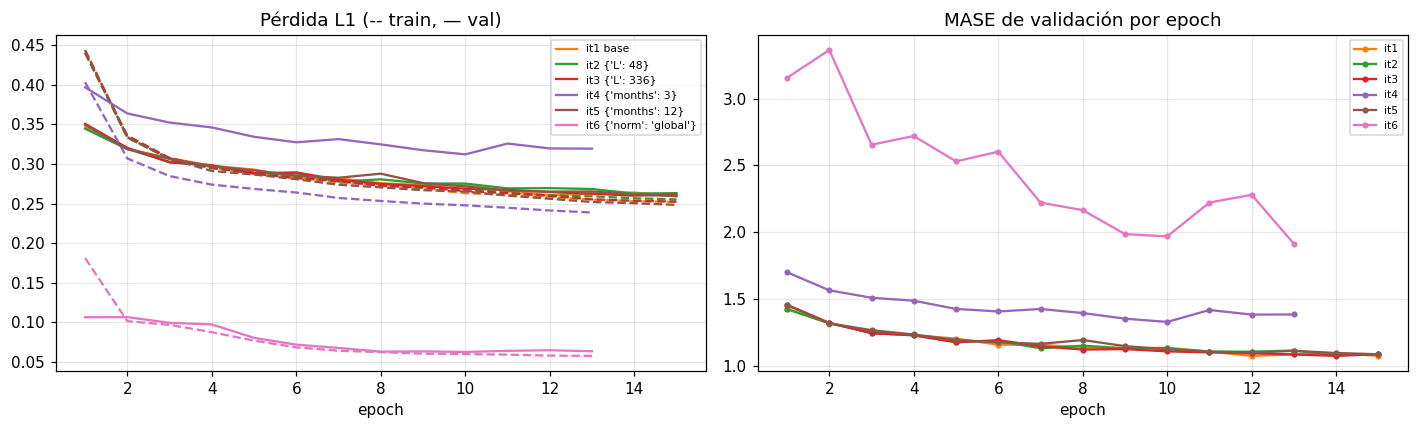

Correlación (train_loss final, val_MASE): -0.545


In [68]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i in list(iter_models)[:6]:
    hst = iter_models[i].history
    ax[0].plot(hst.epoch, hst.train_loss, ls='--', color=f'C{i}'); ax[0].plot(hst.epoch, hst.val_loss, color=f'C{i}', label=f'it{i} {ITER_TBL.cambio[i-1]}')
    ax[1].plot(hst.epoch, hst.val_MASE, marker='o', ms=3, color=f'C{i}', label=f'it{i}')
ax[0].set(title='Pérdida L1 (-- train, — val)', xlabel='epoch'); ax[0].legend(fontsize=7)
ax[1].set(title='MASE de validación por epoch', xlabel='epoch'); ax[1].legend(fontsize=7)
savefig('curvas_perdida')
print('Correlación (train_loss final, val_MASE):', ITER_TBL[['train_loss', 'val_MASE']].corr().iloc[0, 1].round(3))

In [69]:
best_it = int(ITER_TBL.loc[ITER_TBL.val_MASE.idxmin(), 'it']); BEST_OWN_CFG = dict(ITERS[best_it - 1])
print('Mejor iteración:', best_it, BEST_OWN_CFG)
best_rec = iter_models[best_it]
if best_it != 1:                       # la base ya se evaluó en prueba en 5.1
    best_rec.name = f'{ITER_ARCH} (mejor)'; VAL_SCORES[best_rec.name] = ITER_TBL.val_MASE[best_it - 1]
    register(best_rec, backtest(best_rec))
BEST_REC_NAME = best_rec.name

Mejor iteración: 3 {'L': 336}
LSTM-MO (mejor)        MAE=30.919  RMSE=79.477  WAPE=8.190%  MASE=1.019  | train 182.0s  inf 0.9s


In [74]:
import gc; gc.collect(); torch.cuda.empty_cache()

def nf_common(**kw):
    d = dict(h=H, input_size=L, max_steps=NF_STEPS, val_check_steps=20 if FAST else (50 if LITE else 100),
             early_stop_patience_steps=-1 if FAST else (3 if LITE else 5), scaler_type='identity', batch_size=32,
             valid_batch_size=32, windows_batch_size=256, inference_windows_batch_size=512,   # evita OOM en validación
             random_seed=SEED, enable_progress_bar=False, logger=False, enable_model_summary=False)
    d.update(kw); return d

class NFForecaster(Forecaster):
    def __init__(self, build, name, family, strategy, covariates, months=None, quantiles=False, ctx=None, h=H, seed=SEED):
        self.seed = seed
        self.build, self.name, self.family, self.strategy, self.covariates = build, name, family, strategy, covariates
        self.months, self.quantiles, self.H, self.L, self.ctx = months, quantiles, h, L, ctx or 2 * L + h
    def _df(self, Zb, t0):
        df = to_long(Zb, t0); return with_calendar(df) if self.covariates else df
    def fit(self, Y, t_train_end, t_val_end):
        set_seed(self.seed); t0 = history_start(t_train_end, self.months)
        Y = Y[:, :t_val_end]
        self.scaler = PanelScaler('series').fit(Y, t_train_end)      # z-score por serie con stats de train
        Z = self.scaler.transform(Y)
        self.nf = NeuralForecast(models=[self.build(self.seed)], freq='h')
        if DEVICE.type == 'cuda': torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        s = time.perf_counter(); self.nf.fit(df=self._df(Z[:, t0:], t0), val_size=t_val_end - t_train_end)
        self.train_time = time.perf_counter() - s; self.n_params = count_params(self.nf.models[0])
        self.peak_mem = torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == 'cuda' else 0.0
        return self
    def predict(self, hist, t):
        t0 = t - self.ctx
        futr = with_calendar(future_frame(t, self.H)) if self.covariates else None
        fc = self.nf.predict(df=self._df(self.scaler.transform(hist[:, t0:t]), t0), futr_df=futr)
        if 'unique_id' not in fc.columns: fc = fc.reset_index()
        piv = lambda col: self.scaler.inverse(fc.pivot(index='unique_id', columns='ds', values=col).loc[CLIENTS].values)
        if not self.quantiles: return piv(self.name)
        med = piv(f'{self.name}-median') if f'{self.name}-median' in fc.columns else piv(self.name)
        return {'mean': med, 'q': np.stack([piv(f'{self.name}-lo-80'), med, piv(f'{self.name}-hi-80')], -1)}

NF_SPECS = {
    'N-HiTS': (lambda seed=SEED: NHITS(alias='N-HiTS', futr_exog_list=CAL_COLS, n_pool_kernel_size=[4, 2, 1],
                    n_freq_downsample=[24, 12, 1], mlp_units=[[512, 512]] * 3, **nf_common(random_seed=seed)),
               'Residual (MLP)', 'multi-salida', True),
    'TCN': (lambda seed=SEED: TCN(alias='TCN', futr_exog_list=CAL_COLS, kernel_size=3, dilations=[1, 2, 4, 8, 16, 32],
                    encoder_hidden_size=128, decoder_hidden_size=128, **nf_common(random_seed=seed)),
            'Convolucional', 'multi-salida', True),
    'PatchTST': (lambda seed=SEED: PatchTST(alias='PatchTST', patch_len=24, stride=12, hidden_size=128, n_heads=8,
                    **nf_common(random_seed=seed, revin=True)),
                 'Atención', 'multi-salida', False),
    'iTransformer': (lambda seed=SEED: iTransformer(alias='iTransformer', n_series=N, hidden_size=128, n_heads=8,
                    e_layers=2, d_ff=256, **nf_common(random_seed=seed, batch_size=N)),
                     'Atención', 'multi-salida', False),
    'DeepAR': (lambda seed=SEED: DeepAR(alias='DeepAR', futr_exog_list=CAL_COLS, lstm_n_layers=2, lstm_hidden_size=128,
                    trajectory_samples=100, loss=DistributionLoss('StudentT', level=[80]), valid_loss=NF_MAE(),
                    **nf_common(random_seed=seed)),
               'Probabilístico', 'autorregresiva (muestreo)', True),
}

for k in NF_SPECS: RESULTS.pop(k, None)          # descarta los resultados malos anteriores
nf_models = {}
for nm, (build, fam, strat, cov) in NF_SPECS.items():
    if nm in RESULTS: continue
    m = NFForecaster(build, nm, fam, strat, cov, quantiles=(nm == 'DeepAR')).fit(Y_raw, t_val, t_test)
    VAL_SCORES[nm] = val_mase(m); nf_models[nm] = m
    register(m, backtest(m))
    gc.collect(); torch.cuda.empty_cache()

INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=600` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.acce

N-HiTS                 MAE=27.988  RMSE=72.601  WAPE=7.414%  MASE=0.930  | train 71.8s  inf 7.0s


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=600` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: 

TCN                    MAE=27.294  RMSE=74.718  WAPE=7.230%  MASE=0.909  | train 229.2s  inf 6.5s


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=600` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: 

PatchTST               MAE=29.096  RMSE=77.594  WAPE=7.707%  MASE=0.942  | train 52.6s  inf 5.2s


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=600` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: 

iTransformer           MAE=23.790  RMSE=66.647  WAPE=6.302%  MASE=0.776  | train 39.2s  inf 3.3s


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=600` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: 

DeepAR                 MAE=49.508  RMSE=124.445  WAPE=13.114%  MASE=1.641  | train 603.7s  inf 21.1s


### Chronos-Bolt zero-shot

In [75]:
from neuralforecast.models import iTransformer
NF_SPECS.pop('TFT', None)
NF_SPECS['iTransformer'] = (lambda seed=SEED: iTransformer(alias='iTransformer', n_series=N, hidden_size=128, n_heads=8,
                                                           e_layers=2, d_ff=256, **nf_common(random_seed=seed, batch_size=N)),
                            'Atención', 'multi-salida', False)
for nm, (build, fam, strat, cov) in NF_SPECS.items():
    if nm in RESULTS: continue          # salta N-HiTS, TCN y PatchTST, que ya están
    m = NFForecaster(build, nm, fam, strat, cov, quantiles=(nm == 'DeepAR')).fit(Y_raw, t_val, t_test)
    VAL_SCORES[nm] = val_mase(m); nf_models[nm] = m
    register(m, backtest(m))

In [76]:
from chronos import BaseChronosPipeline

class ChronosForecaster(Forecaster):
    family, strategy, covariates = 'Fundacional', 'multi-salida (cuantiles)', False
    def __init__(self, model_id='amazon/chronos-bolt-small', ctx=2048, h=H, name='Chronos-Bolt'):
        self.pipe = BaseChronosPipeline.from_pretrained(model_id, device_map=str(DEVICE), torch_dtype=torch.float32)
        self.name, self.ctx, self.H, self.L = name, ctx, h, ctx
        self.n_params = count_params(self.pipe.model)
    @torch.no_grad()
    def predict(self, hist, t):
        ctx = torch.tensor(hist[:, max(0, t - self.ctx):t], dtype=torch.float32)
        q, _ = self.pipe.predict_quantiles(ctx, prediction_length=self.H, quantile_levels=QLEVELS.tolist())
        q = q.float().cpu().numpy(); return {'mean': q[..., 1], 'q': q}

chronos = ChronosForecaster()
VAL_SCORES['Chronos-Bolt'] = val_mase(chronos)
register(chronos, backtest(chronos))

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Chronos-Bolt           MAE=22.821  RMSE=65.283  WAPE=6.045%  MASE=0.746  | train 0.0s  inf 20.3s


{'MAE': np.float64(22.820709804391516),
 'RMSE': np.float64(65.28255538460638),
 'WAPE': np.float64(0.06045085671145432),
 'MAPE': np.float64(8.068028338505606),
 'MAPE_peor_cliente': np.float64(40.41153731239228),
 'MASE': np.float64(0.7455931995499152),
 'Pinball': np.float64(7.634742182601334),
 'Cobertura_P10_P90': np.float64(0.8000452898550725),
 'MASE_dic22_28': np.float64(1.3365105443879421)}

In [77]:
MONTHS = [3, 12, 30]
hist_curve = {'SNaive24': {mo: VAL_SCORES['SNaive24'] for mo in MONTHS}}
hist_curve['LightGBM'] = {30: VAL_SCORES['LightGBM']}
hist_curve['DLinear'] = {30: VAL_SCORES['DLinear']}
hist_curve[ITER_ARCH] = {mo: ITER_TBL.loc[(ITER_TBL.meses == mo) & ITER_TBL.cambio.isin(['base', f"{{'months': {mo}}}"]), 'val_MASE'].iloc[0]
                         for mo in MONTHS if ((ITER_TBL.meses == mo) & ITER_TBL.cambio.isin(['base', f"{{'months': {mo}}}"])).any()}
hist_curve['PatchTST'] = {30: VAL_SCORES['PatchTST']}
for mo in MONTHS[:-1]:
    hist_curve['LightGBM'][mo] = val_mase(LGBMForecaster(months=mo).fit(Y_raw, t_val, t_test))
    hist_curve['DLinear'][mo]  = val_mase(TorchForecaster('DLinear', months=mo).fit(Y_raw, t_val, t_test))
    b, f, s_, c_ = NF_SPECS['PatchTST']
    hist_curve['PatchTST'][mo] = val_mase(NFForecaster(b, 'PatchTST', f, s_, c_, months=mo).fit(Y_raw, t_val, t_test))
HIST_TBL = pd.DataFrame(hist_curve).sort_index(); display(HIST_TBL.round(4)); HIST_TBL.to_csv(f'{OUT}/mase_vs_historia.csv')

INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=600` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.acce

,SNaive24,LightGBM,DLinear,LSTM-MO,PatchTST
3,0.9955,0.9366,0.8912,1.3288,0.9616
12,0.9955,0.8452,0.9125,1.0868,1.0107
30,0.9955,0.8247,0.9027,1.0753,0.9826


In [78]:
rng10 = np.random.default_rng(SEED); LOCAL_IDX = np.sort(rng10.choice(N, 10, replace=False))

class LocalEnsemble(Forecaster):
    def __init__(self, arch, cfg, idx):
        self.idx, self.models = idx, {}
        self.name, self.arch = f'{arch} local', arch
        for s in idx:
            self.models[s] = TorchForecaster(arch, name=f'{arch}-c{s}', series=[int(s)], **cfg).fit(Y_raw, t_val, t_test)
        self.train_time = sum(m.train_time for m in self.models.values())
    def predict(self, hist, t):
        out = np.full((N, H), np.nan)
        for s, m in self.models.items(): out[s] = m.predict(hist, t)[s]
        return out

local = LocalEnsemble(ITER_ARCH, BEST_OWN_CFG, LOCAL_IDX)
r_loc, r_glob = backtest(local), RESULTS[BEST_REC_NAME]['res']
pick = lambda r: {**r, 'yhat': r['yhat'][LOCAL_IDX], 'y': r['y'][LOCAL_IDX]}
mase_c = lambda r: np.abs(r['yhat'] - r['y']).mean((1, 2)) / SCALE24[LOCAL_IDX]
LOCAL_TBL = pd.DataFrame({'cliente': CLIENTS[LOCAL_IDX], 'consumo_medio': mean_train[LOCAL_IDX],
                          'MASE_local': mase_c(pick(r_loc)), 'MASE_global': mase_c(pick(r_glob))})
LOCAL_TBL['mejora_global_%'] = 100 * (1 - LOCAL_TBL.MASE_global / LOCAL_TBL.MASE_local)
display(LOCAL_TBL.round(3)); print('Promedio MASE local:', LOCAL_TBL.MASE_local.mean().round(4), '| global:', LOCAL_TBL.MASE_global.mean().round(4))
print('Tiempo total locales:', round(local.train_time, 1), 's')
LOCAL_TBL.to_csv(f'{OUT}/local_vs_global.csv', index=False)

,cliente,consumo_medio,MASE_local,MASE_global,mejora_global_%
0,MT_035,116.417999,0.819,1.000,-21.974
1,MT_045,92.471001,0.608,0.765,-25.858
2,MT_091,142.363998,0.866,0.911,-5.234
3,MT_166,1252.770996,1.043,1.096,-5.053
4,MT_240,354.437988,1.030,1.011,1.878
5,MT_254,242.104004,0.834,1.032,-23.720
6,MT_259,153.272995,0.943,1.044,-10.705
7,MT_298,935.435974,0.944,0.921,2.425
8,MT_344,170.942993,0.920,0.940,-2.178
9,MT_358,802.908997,0.936,1.028,-9.777


Promedio MASE local: 0.8944 | global: 0.9748
Tiempo total locales: 1062.2 s


In [79]:
DL_FAMILIES = {'MLP/lineal', 'Recurrente', 'Encoder-decoder', 'Residual (MLP)', 'Convolucional', 'Atención', 'Probabilístico'}
best_dl = min([k for k, v in RESULTS.items() if v['family'] in DL_FAMILIES], key=lambda k: VAL_SCORES.get(k, np.inf))
best_base = min([k for k, v in RESULTS.items() if v['family'] == 'Baseline'], key=lambda k: VAL_SCORES.get(k, np.inf))
print('Mejor DL (val):', best_dl, '| mejor baseline (val):', best_base)

def factory_for(name):
    m = RESULTS[name]['model']
    if isinstance(m, TorchForecaster): return lambda: TorchForecaster(m.arch, name=m.name, **{k: v for k, v in m.cfg.items()})
    if isinstance(m, NFForecaster):    return lambda: NFForecaster(m.build, m.name, m.family, m.strategy, m.covariates, quantiles=m.quantiles)
    if isinstance(m, LGBMForecaster):  return lambda: LGBMForecaster()
    return lambda: m                   # estadístico: fit no hace nada (se re-estima en cada origen)

REFIT = {}
for nm in [best_dl, best_base, 'LightGBM']:
    r = backtest_monthly_refit(factory_for(nm)); e = evaluate(r)
    REFIT[nm] = dict(MASE_una_vez=RESULTS[nm]['metrics']['MASE'], MASE_reentreno_mensual=e['MASE'],
                     MAE_una_vez=RESULTS[nm]['metrics']['MAE'], MAE_reentreno_mensual=e['MAE'])
REFIT_TBL = pd.DataFrame(REFIT).T; display(REFIT_TBL.round(4)); REFIT_TBL.to_csv(f'{OUT}/reentrenamiento.csv')

INFO:lightning_fabric.utilities.seed:Seed set to 42


Mejor DL (val): iTransformer | mejor baseline (val): SNaive24


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=600` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: 

,MASE_una_vez,MASE_reentreno_mensual,MAE_una_vez,MAE_reentreno_mensual
iTransformer,0.7758,0.7777,23.7896,23.8307
SNaive24,1.0113,1.0113,30.8910,30.8910
LightGBM,0.7795,0.7777,23.4671,23.3950


### MASE con H = 168 (orígenes semanales en prueba)

In [80]:
ORIG168 = np.arange(t_test, T - 168 + 1, 168)
MASE168 = {}
MASE168['SNaive168'] = evaluate(backtest(SFForecaster(SeasonalNaive(168, alias='SNaive168'), 'SNaive168', 24 * 14, h=168), ORIG168, h=168))['MASE']
for arch in ['DLinear', 'NLinear', ITER_ARCH]:
    cfg = {**BEST_OWN_CFG} if arch == ITER_ARCH else {}
    cfg.update(H=168, L=max(cfg.get('L', 168), 336))
    MASE168[arch if arch != ITER_ARCH else BEST_REC_NAME] = evaluate(
        backtest(TorchForecaster(arch, **cfg).fit(Y_raw, t_val, t_test), ORIG168, h=168))['MASE']
MASE168['Chronos-Bolt'] = evaluate(backtest(ChronosForecaster(h=168), ORIG168, h=168))['MASE']
for k, v in MASE168.items():
    if k in RESULTS: RESULTS[k]['metrics']['MASE_H168'] = v
print({k: round(v, 4) for k, v in MASE168.items()})

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

{'SNaive168': np.float64(1.0685), 'DLinear': np.float64(0.9561), 'NLinear': np.float64(0.9518), 'LSTM-MO (mejor)': np.float64(1.2477), 'Chronos-Bolt': np.float64(0.9046)}


### Sensibilidad a la semilla (mejor modelo, 3 semillas)

In [81]:
SEEDS = [42, 43, 44]
best_name = min([k for k, v in RESULTS.items() if v['family'] in DL_FAMILIES | {'Árboles'}], key=lambda k: VAL_SCORES.get(k, np.inf))
seed_mase = []
for sd in SEEDS:
    m = RESULTS[best_name]['model']
    if isinstance(m, TorchForecaster): mm = TorchForecaster(m.arch, **{**m.cfg, 'seed': sd})
    elif isinstance(m, LGBMForecaster): mm = LGBMForecaster(seed=sd)
    else:
        mm = NFForecaster(m.build, m.name, m.family, m.strategy, m.covariates, quantiles=m.quantiles, seed=sd)
    seed_mase.append(evaluate(backtest(mm.fit(Y_raw, t_val, t_test)))['MASE'])
print(best_name, 'MASE por semilla:', np.round(seed_mase, 4), '| media', np.mean(seed_mase).round(4), '± std', np.std(seed_mase, ddof=1).round(4))

LightGBM MASE por semilla: [0.7795 0.7865 0.7771] | media 0.781 ± std 0.0049


In [82]:
rows = []
for k, v in RESULTS.items():
    m = v['metrics']
    rows.append({'Modelo': k, 'Familia': v['family'], 'L': v['L'], 'Estrategia': v['strategy'], 'Covariables': 'sí' if v['covariates'] else 'no',
                 'Params tot': v['n_params'][0], 'Params entr': v['n_params'][1],
                 'T. train (s)': v['train_time'], 'T. inf 92 (s)': v['inf_time'], 'Hardware': HARDWARE,
                 'MAE': m['MAE'], 'RMSE': m['RMSE'], 'WAPE': m['WAPE'], 'MAPE': m['MAPE'], 'MASE': m['MASE'],
                 'MASE H=168': m.get('MASE_H168', np.nan), 'MASE 22-28 dic': m['MASE_dic22_28'],
                 'Pinball': m.get('Pinball', np.nan), 'Cob. P10-P90': m.get('Cobertura_P10_P90', np.nan),
                 'MASE val': VAL_SCORES.get(k, np.nan)})
COMP = pd.DataFrame(rows).sort_values('MASE').reset_index(drop=True)
COMP.to_csv(f'{OUT}/tabla_comparativa.csv', index=False)
display(COMP.drop(columns='Hardware').round(4))
sn = RESULTS['SNaive24']['metrics']['MASE']; w = COMP.iloc[0]
print(f"Ganador: {w.Modelo} — MASE {w.MASE:.4f} vs SNaive24 {sn:.4f} ({100*(1-w.MASE/sn):.1f}% mejor)")

,Modelo,Familia,L,Estrategia,Covariables,Params tot,Params entr,T. train (s),T. inf 92 (s),MAE,RMSE,WAPE,MAPE,MASE,MASE H=168,MASE 22-28 dic,Pinball,Cob. P10-P90,MASE val
0,Chronos-Bolt,Fundacional,2048,multi-salida (cuantiles),no,47718016,47718016,0.0000,20.3307,22.8207,65.2826,0.0605,8.0680,0.7456,0.9046,1.3365,7.6347,0.8000,0.7837
1,iTransformer,Atención,168,multi-salida,no,289944,289944,39.2272,3.2922,23.7896,66.6466,0.0630,8.9491,0.7758,NaN,1.3520,NaN,NaN,0.8263
2,LightGBM,Árboles,168,directa (h como feature),sí,151547,151547,75.7552,24.7966,23.4671,66.1288,0.0622,8.4897,0.7795,NaN,1.3115,NaN,NaN,0.8247
3,DLinear,MLP/lineal,168,multi-salida,no,8112,8112,10.0907,0.0979,27.2380,77.0670,0.0722,10.7528,0.8717,0.9561,1.7185,NaN,NaN,0.9027
4,NLinear,MLP/lineal,168,multi-salida,no,4056,4056,9.9341,0.0730,27.3191,77.0286,0.0724,10.7749,0.8753,0.9518,1.7155,NaN,NaN,0.9083
5,TCN,Convolucional,168,multi-salida,sí,271705,271705,229.1583,6.5092,27.2936,74.7185,0.0723,10.4266,0.9088,NaN,1.5871,NaN,NaN,0.9688
6,N-HiTS,Residual (MLP),168,multi-salida,sí,4164627,4164627,71.7757,7.0387,27.9880,72.6010,0.0741,10.4186,0.9303,NaN,1.4757,NaN,NaN,0.9906
7,PatchTST,Atención,168,multi-salida,no,445467,445464,52.5795,5.1748,29.0955,77.5940,0.0771,11.7490,0.9420,NaN,1.7519,NaN,NaN,0.9826
8,MSTL,Baseline,336,multi-salida,no,0,0,0.0000,1100.4185,29.9510,84.2469,0.0793,11.4637,0.9624,NaN,1.7979,NaN,NaN,1.0610
9,MLP,MLP/lineal,168,multi-salida,sí,1147928,1147928,6.0763,0.0973,29.1991,75.1742,0.0773,11.0357,0.9636,NaN,1.4870,NaN,NaN,1.0052


Ganador: Chronos-Bolt — MASE 0.7456 vs SNaive24 1.0113 (26.3% mejor)


In [83]:
# MAPE y clientes de consumo cercano a cero
pc = per_client(RESULTS[COMP.Modelo[0]]['res']); pc['consumo_medio'] = mean_train
y_, p_ = RESULTS[COMP.Modelo[0]]['res']['y'], RESULTS[COMP.Modelo[0]]['res']['yhat']
pc['MAPE'] = [np.mean(np.abs(p_[i] - y_[i])[y_[i] > 0] / y_[i][y_[i] > 0]) * 100 for i in range(N)]
print('Clientes con menor consumo (MAPE explota):'); display(pc.sort_values('consumo_medio').head(5).round(3))
pc.to_csv(f'{OUT}/metricas_por_cliente_mejor.csv', index=False)

Clientes con menor consumo (MAPE explota):


,cliente,MAE,RMSE,MASE,consumo_medio,MAPE
34,MT_141,0.149,0.289,0.474,8.077000,1.323
2,MT_019,0.790,1.052,0.744,8.282000,9.681
20,MT_096,1.553,2.423,0.498,11.067000,15.621
7,MT_026,2.148,3.093,0.716,20.864000,9.016
5,MT_022,3.736,6.047,0.709,27.096001,13.011


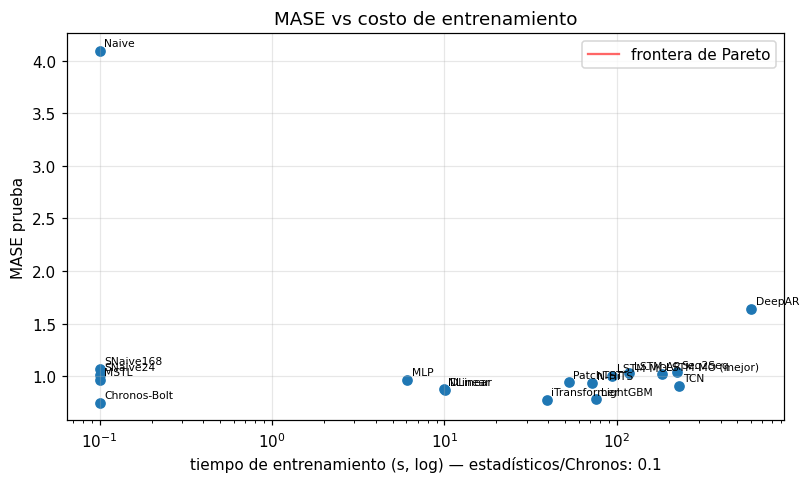

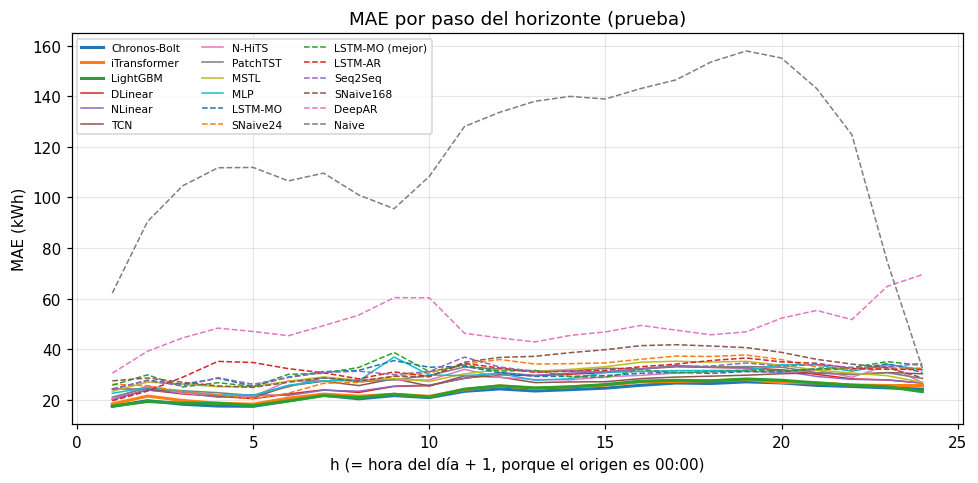

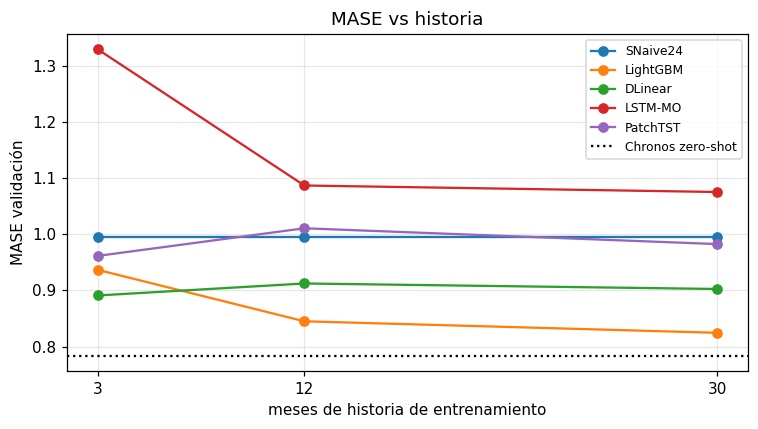

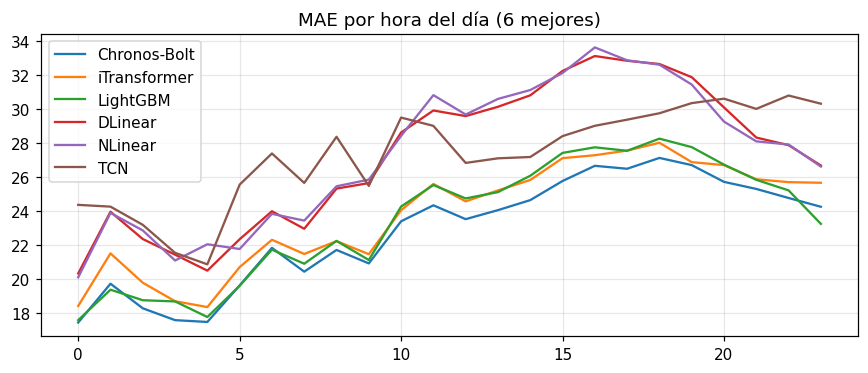

In [84]:
# (1) Pareto MASE vs tiempo de entrenamiento
fig, ax = plt.subplots(figsize=(7.5, 4.5))
d = COMP.assign(tt=COMP['T. train (s)'].clip(lower=0.1))
ax.scatter(d.tt, d.MASE)
for _, r in d.iterrows(): ax.annotate(r.Modelo, (r.tt, r.MASE), fontsize=7, xytext=(3, 3), textcoords='offset points')
ds_ = d.sort_values('tt'); front = ds_[ds_.MASE <= ds_.MASE.cummin()]
ax.step(front.tt, front.MASE, where='post', color='red', alpha=.6, label='frontera de Pareto')
ax.set(xscale='log', xlabel='tiempo de entrenamiento (s, log) — estadísticos/Chronos: 0.1', ylabel='MASE prueba', title='MASE vs costo de entrenamiento')
ax.legend(); savefig('pareto')

# (2) MAE por paso del horizonte
plt.figure(figsize=(9, 4.5))
for i, k in enumerate(COMP.Modelo):
    plt.plot(range(1, H + 1), per_step(RESULTS[k]['res']), label=k, lw=2 if i < 3 else 1, ls='-' if i < 10 else '--')
plt.xlabel('h (= hora del día + 1, porque el origen es 00:00)'); plt.ylabel('MAE (kWh)'); plt.title('MAE por paso del horizonte (prueba)')
plt.legend(fontsize=7, ncol=3); savefig('mae_por_paso')

# (3) MASE vs meses de historia
plt.figure(figsize=(7, 4))
for col in HIST_TBL.columns: plt.plot(HIST_TBL.index, HIST_TBL[col], marker='o', label=col)
plt.axhline(VAL_SCORES['Chronos-Bolt'], color='k', ls=':', label='Chronos zero-shot')
plt.xticks(MONTHS); plt.xlabel('meses de historia de entrenamiento'); plt.ylabel('MASE validación'); plt.title('MASE vs historia'); plt.legend(fontsize=8)
savefig('mase_vs_historia')

# Error por hora del día y semana navideña
ph = pd.DataFrame({k: per_hour(RESULTS[k]['res']) for k in COMP.Modelo[:6]}); ph.to_csv(f'{OUT}/mae_por_hora.csv')
ph.plot(figsize=(8, 3.5), title='MAE por hora del día (6 mejores)'); savefig('mae_por_hora')

### Resultados probabilísticos (DeepAR y Chronos)

,Pinball,Cobertura_P10_P90,MASE
Chronos-Bolt,7.6347,0.8000,0.7456
DeepAR,17.3899,0.5533,1.6411


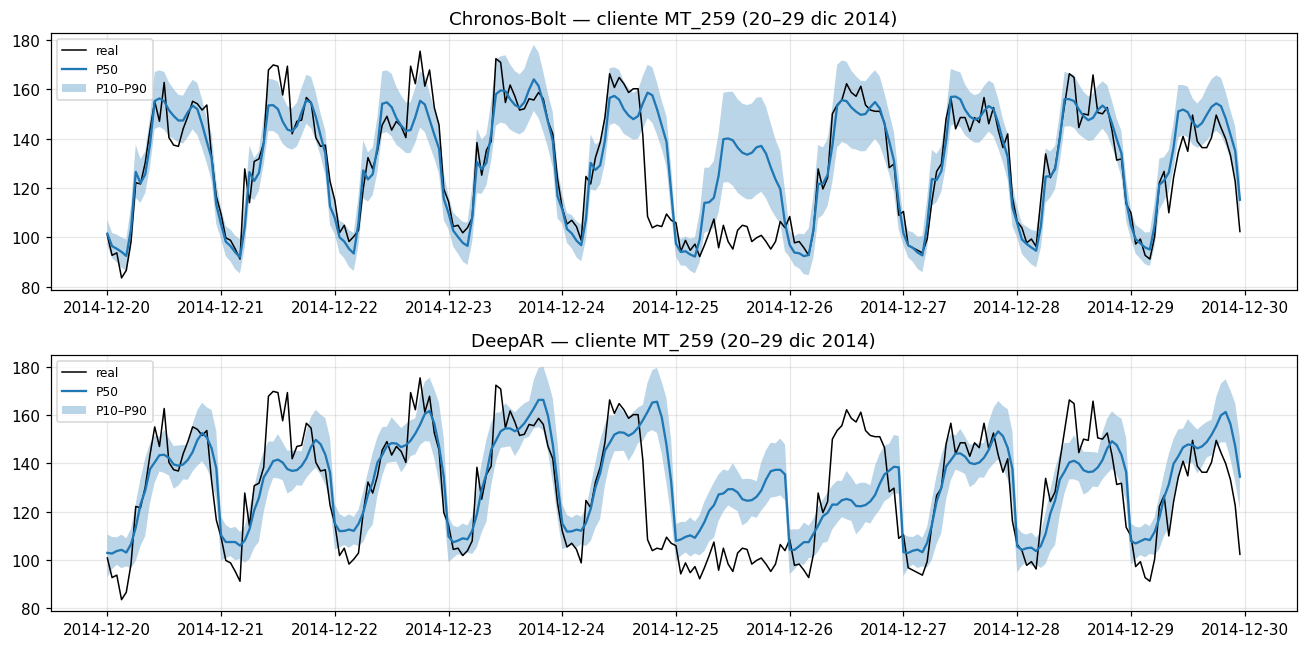

In [85]:
PROB = pd.DataFrame({k: {m_: RESULTS[k]['metrics'][m_] for m_ in ['Pinball', 'Cobertura_P10_P90', 'MASE']}
                     for k in RESULTS if RESULTS[k]['res']['q'] is not None}).T
display(PROB.round(4)); PROB.to_csv(f'{OUT}/probabilisticos.csv')
s_ex = int(np.argsort(mean_train)[N // 2]); o_sel = np.where(DATES[TEST_ORIGINS] >= pd.Timestamp('2014-12-20'))[0][:10]
fig, axs = plt.subplots(len(PROB), 1, figsize=(12, 3 * len(PROB)), squeeze=False)
for ax, k in zip(axs[:, 0], PROB.index):
    r = RESULTS[k]['res']; ts = DATES[(r['origins'][o_sel, None] + np.arange(H)).ravel()]
    ax.plot(ts, r['y'][s_ex, o_sel].ravel(), 'k', lw=1, label='real')
    ax.plot(ts, r['q'][s_ex, o_sel, :, 1].ravel(), label='P50')
    ax.fill_between(ts, r['q'][s_ex, o_sel, :, 0].ravel(), r['q'][s_ex, o_sel, :, 2].ravel(), alpha=.3, label='P10–P90')
    ax.set_title(f'{k} — cliente {CLIENTS[s_ex]} (20–29 dic 2014)'); ax.legend(fontsize=8)
savefig('fan_chart')

### Navidad y Año Nuevo en prueba

In [86]:
def window_mase(res, a, b):
    ds = ds_grid(res)
    return evaluate(res, (ds >= np.datetime64(a)) & (ds < np.datetime64(b)))['MASE']
XMAS = pd.DataFrame({k: {'oct–nov (normal)': window_mase(RESULTS[k]['res'], '2014-10-01', '2014-12-01'),
                         '22–28 dic': RESULTS[k]['metrics']['MASE_dic22_28'],
                         '24–26 dic': window_mase(RESULTS[k]['res'], '2014-12-24', '2014-12-27'),
                         '31 dic': window_mase(RESULTS[k]['res'], '2014-12-31', '2015-01-01')} for k in COMP.Modelo}).T
XMAS['deterioro_22_28_%'] = 100 * (XMAS['22–28 dic'] / XMAS['oct–nov (normal)'] - 1)
display(XMAS.round(3)); XMAS.to_csv(f'{OUT}/navidad_test.csv')

,oct–nov (normal),22–28 dic,24–26 dic,31 dic,deterioro_22_28_%
Chronos-Bolt,0.695,1.337,2.129,1.396,92.242
iTransformer,0.727,1.352,2.070,1.420,85.973
LightGBM,0.724,1.311,1.964,1.371,81.207
DLinear,0.812,1.718,2.871,1.470,111.725
NLinear,0.817,1.716,2.858,1.458,110.035
TCN,0.848,1.587,2.491,1.543,87.199
N-HiTS,0.886,1.476,2.239,1.538,66.647
PatchTST,0.878,1.752,2.837,1.738,99.648
MSTL,0.893,1.798,2.819,1.836,101.391
MLP,0.913,1.487,2.225,1.669,62.953


### Exportar pronósticos de prueba `(unique_id, ds, modelo, y_hat)`

In [87]:
parts = []
for k, v in RESULTS.items():
    r = v['res']; ds = DATES[(r['origins'][:, None] + np.arange(r['h'])).ravel()]
    parts.append(pd.DataFrame({'unique_id': np.repeat(CLIENTS, len(ds)), 'ds': np.tile(ds.values, N),
                               'modelo': k, 'y_hat': r['yhat'].reshape(N, -1).ravel().astype(np.float32)}))
FC = pd.concat(parts, ignore_index=True)
FC.to_csv(f'{OUT}/pronosticos_prueba.csv.gz', index=False, compression='gzip')
print(FC.shape); FC.head()

(3974400, 4)


,unique_id,ds,modelo,y_hat
0,MT_013,2014-10-01 00:00:00,Naive,54.311775
1,MT_013,2014-10-01 01:00:00,Naive,54.311775
2,MT_013,2014-10-01 02:00:00,Naive,54.311775
3,MT_013,2014-10-01 03:00:00,Naive,54.311775
4,MT_013,2014-10-01 04:00:00,Naive,54.311775
